<a href="https://colab.research.google.com/github/ajithraphaelthomas/colab-git-assignment2-ART/blob/main/Assignment_5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Github Repository:

Colab Notebook: https://colab.research.google.com/drive/1RwHDPMMVUS4yWh8-SCndeXVhcqZKG-Yo?usp=sharing

**Assignment - EDA using Pandas**

***Instructions***
- Clone a copy of the assignment notebook in Google Colab.
- **Complete the tasks by filling in the code where indicated by TODO comments. Put each task in a new cell.**
- Run each cell to ensure your code works correctly.
- Pay attention to the output of each cell and interpret the results.
- For visualisation tasks, make sure to label axes, add titles, and choose appropriate colour schemes.
- After completing all tasks, review your findings and include notes of your insights gained from the EDA process as markdown notes for assessments.


In [3]:
# Titanic Dataset Exploratory Data Analysis

# Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Task 1: Load the Titanic dataset
# TODO: Load the Titanic dataset from the following URL
#url = "https://web.stanford.edu/class/archive/cs/cs109/cs109.1166/stuff/titanic.csv"
url =  "/content/Titanic-Dataset.csv"
df = pd.read_csv(url)

print("Dataset shape:", df.shape)

Dataset shape: (891, 12)


This assignment explores the Titanic dataset using Pandas, Matplotlib, and Seaborn. The dataset contains information about 891 passengers, including their age, sex, passenger class, fare, and survival status.

The objective is to clean the dataset, handle missing values, manipulate data using Pandas, and create visualizations to identify factors associated with passenger survival.

In [5]:
# Task 2: Inspect the data
# TODO: Display the first 5 rows of the dataset
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [6]:
# TODO: Display the last 5 rows of the dataset
df.tail()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.00,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.00,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.45,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.00,C148,C
890,891,0,3,"Dooley, Mr. Patrick",male,32.0,0,0,370376,7.75,NaN,Q


In [7]:
# TODO: Display the data types of each column
df.dtypes

,0
PassengerId,int64
Survived,int64
Pclass,int64
Name,object
Sex,object
Age,float64
SibSp,int64
Parch,int64
Ticket,object
Fare,float64


In [8]:
# TODO: Display summary statistics of the numerical columns
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


The Titanic dataset contains 891 passenger records and 12 columns.

The head() and tail() functions display the first and last five records, helping us understand the structure of the dataset.

The dtypes function identifies numerical and categorical columns, while describe() provides statistical information such as mean, minimum, maximum, and standard deviation.

The info() function shows the number of non-null values in each column and helps identify missing data.

Observations:

The dataset contains both numerical and categorical variables.

The Age column contains missing values.

The Cabin column has a large number of missing values.

The Fare column contains a wide range of ticket prices.

These observations indicate that data cleaning and preprocessing are necessary before performing further analysis.

In [9]:
# Task 3: Clean and preprocess the data

# TODO: Create a new categorical feature 'PclassCategory' from 'Pclass'
df['PclassCategory'] = df['Pclass'].map({
    1: 'First Class',
    2: 'Second Class',
    3: 'Third Class'
})

In [10]:
# TODO: Create a new categorical feature 'CabinCategory' from 'Cabin'
# Extract the first letter of the cabin number
df['CabinCategory'] = df['Cabin'].str[0].fillna('Unknown')

In [11]:
# TODO: Handle missing values in the 'Age' column (use mean age)
df['Age'] = df['Age'].fillna(df['Age'].mean())

In [12]:
# TODO: Create a 'Family' feature by combining 'SibSp' and 'Parch'
df['Family'] = df['SibSp'] + df['Parch'] + 1

In [13]:
# Display the updated dataset
print(df[['PclassCategory', 'CabinCategory', 'Age', 'Family']].head())

  PclassCategory CabinCategory   Age  Family
0    Third Class       Unknown  22.0       2
1    First Class             C  38.0       2
2    Third Class       Unknown  26.0       1
3    First Class             C  35.0       2
4    Third Class       Unknown  35.0       1


In [15]:
# Check missing Age values after preprocessing
print("\nMissing Age values:", df['Age'].isnull().sum())


Missing Age values: 0


The dataset was cleaned and preprocessed to prepare it for analysis.

* PclassCategory: Converted numerical passenger classes into First Class, Second Class, and Third Class.

* CabinCategory: Extracted the first letter of the cabin number to identify cabin categories. Missing values were labeled as Unknown.

* Age: Replaced missing age values with the mean age to ensure the column contains no missing values.

* Family: Created a new feature by combining SibSp (siblings/spouses), Parch (parents/children), and the passenger.

These preprocessing steps make the dataset more suitable for exploratory data analysis and visualization.

In [16]:
# Task 4: Identify specific data points

# TODO: Find passengers with the highest fare
highest_fare_passengers = df[df['Fare'] == df['Fare'].max()]
print(highest_fare_passengers)

     PassengerId  Survived  Pclass                                Name  \
258          259         1       1                    Ward, Miss. Anna   
679          680         1       1  Cardeza, Mr. Thomas Drake Martinez   
737          738         1       1              Lesurer, Mr. Gustave J   

        Sex   Age  SibSp  Parch    Ticket      Fare        Cabin Embarked  \
258  female  35.0      0      0  PC 17755  512.3292          NaN        C   
679    male  36.0      0      1  PC 17755  512.3292  B51 B53 B55        C   
737    male  35.0      0      0  PC 17755  512.3292         B101        C   

    PclassCategory CabinCategory  Family  
258    First Class       Unknown       1  
679    First Class             B       2  
737    First Class             B       1  


In [17]:
# TODO: Find passengers with the largest family size
largest_family_passengers = df[df['Family'] == df['Family'].max()]
print(largest_family_passengers)

     PassengerId  Survived  Pclass                               Name     Sex  \
159          160         0       3         Sage, Master. Thomas Henry    male   
180          181         0       3       Sage, Miss. Constance Gladys  female   
201          202         0       3                Sage, Mr. Frederick    male   
324          325         0       3           Sage, Mr. George John Jr    male   
792          793         0       3            Sage, Miss. Stella Anna  female   
846          847         0       3           Sage, Mr. Douglas Bullen    male   
863          864         0       3  Sage, Miss. Dorothy Edith "Dolly"  female   

           Age  SibSp  Parch    Ticket   Fare Cabin Embarked PclassCategory  \
159  29.699118      8      2  CA. 2343  69.55   NaN        S    Third Class   
180  29.699118      8      2  CA. 2343  69.55   NaN        S    Third Class   
201  29.699118      8      2  CA. 2343  69.55   NaN        S    Third Class   
324  29.699118      8      2  CA. 2

The max() function was used to identify the highest ticket fare and the largest family size in the Titanic dataset.

The highest recorded fare was approximately 512.33, while the largest family size was 11 members, including the passenger.

Boolean indexing was used to retrieve all passengers matching these maximum values. This demonstrates how Pandas can filter records based on specific conditions.

In [18]:
# Task 5: Demonstrate Pandas Series and DataFrame functionalities

# TODO: Create a Pandas Series of passenger names
names_series = df['Name']
print(names_series.head())

0                              Braund, Mr. Owen Harris
1    Cumings, Mrs. John Bradley (Florence Briggs Th...
2                               Heikkinen, Miss. Laina
3         Futrelle, Mrs. Jacques Heath (Lily May Peel)
4                             Allen, Mr. William Henry
Name: Name, dtype: object


In [19]:
# TODO: Create a DataFrame of passenger names and ages
names_ages_df = df[['Name', 'Age']]
print(names_ages_df.head())

                                                Name   Age
0                            Braund, Mr. Owen Harris  22.0
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  38.0
2                             Heikkinen, Miss. Laina  26.0
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  35.0
4                           Allen, Mr. William Henry  35.0


In [20]:
# TODO: Slice the DataFrame to show only passengers older than 50
older_passengers = names_ages_df[names_ages_df['Age'] > 50]
print(older_passengers)

                                                  Name   Age
6                              McCarthy, Mr. Timothy J  54.0
11                            Bonnell, Miss. Elizabeth  58.0
15                    Hewlett, Mrs. (Mary D Kingcome)   55.0
33                               Wheadon, Mr. Edward H  66.0
54                      Ostby, Mr. Engelhart Cornelius  65.0
..                                                 ...   ...
820  Hays, Mrs. Charles Melville (Clara Jennings Gr...  52.0
829          Stone, Mrs. George Nelson (Martha Evelyn)  62.0
851                                Svensson, Mr. Johan  74.0
857                             Daly, Mr. Peter Denis   51.0
879      Potter, Mrs. Thomas Jr (Lily Alexenia Wilson)  56.0

[64 rows x 2 columns]


A Pandas Series was created to store passenger names, while a DataFrame was created to store passenger names and ages.

Boolean indexing was used to filter passengers older than 50 years.

In [21]:
# Task 6: Introduce multi-indexing

# TODO: Create a multi-index DataFrame grouped by 'Sex' and 'Pclass'
multi_index_df = df.groupby(['Sex', 'Pclass'])['Survived'].mean().to_frame('SurvivalRate')
print(multi_index_df)

               SurvivalRate
Sex    Pclass              
female 1           0.968085
       2           0.921053
       3           0.500000
male   1           0.368852
       2           0.157407
       3           0.135447


A multi-index DataFrame was created using the Sex and Pclass columns to calculate survival rates for different passenger groups.

The analysis shows that female passengers had higher survival rates than male passengers across all three classes.

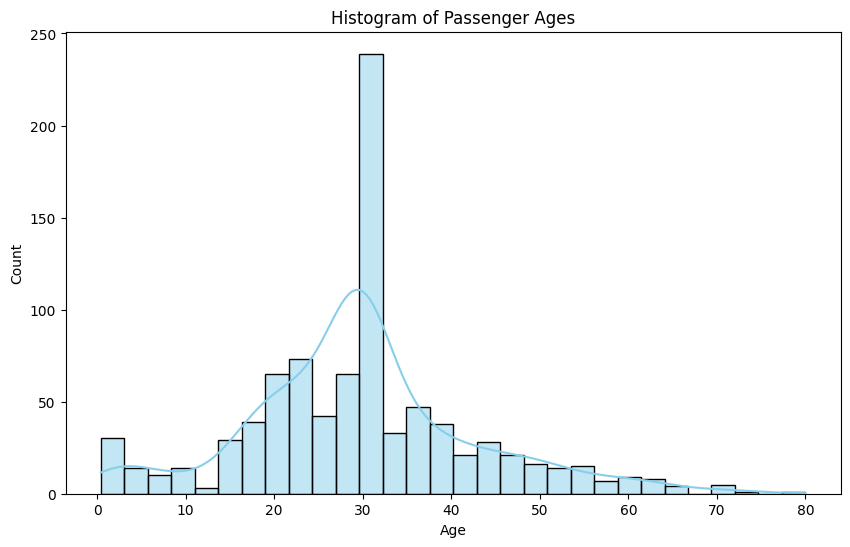

In [22]:
# Task 7: Visualizations

# TODO: Create a histogram of passenger ages
plt.figure(figsize=(10, 6))
sns.histplot(data=df, x='Age', bins=30, kde=True, color='skyblue')
plt.title('Histogram of Passenger Ages')
plt.xlabel('Age')
plt.ylabel('Count')
plt.show()

The histogram shows the age distribution of Titanic passengers. Most passengers were between 20 and 40 years old. A noticeable concentration around the mean age is expected because missing ages were filled using the mean.

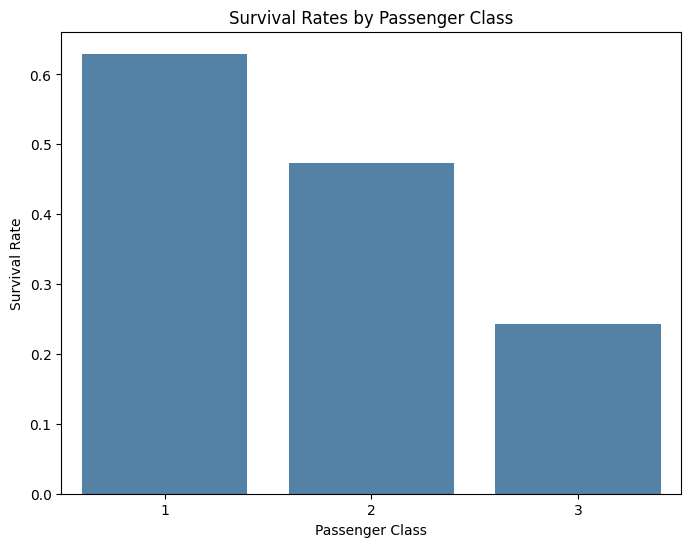

In [23]:
# TODO: Create a bar plot of survival rates by passenger class

plt.figure(figsize=(8, 6))
sns.barplot(data=df, x='Pclass', y='Survived', color='steelblue', errorbar=None)
plt.title('Survival Rates by Passenger Class')
plt.xlabel('Passenger Class')
plt.ylabel('Survival Rate')
plt.show()

The bar plot shows that first-class passengers had the highest survival rate, followed by second-class passengers and third-class passengers.

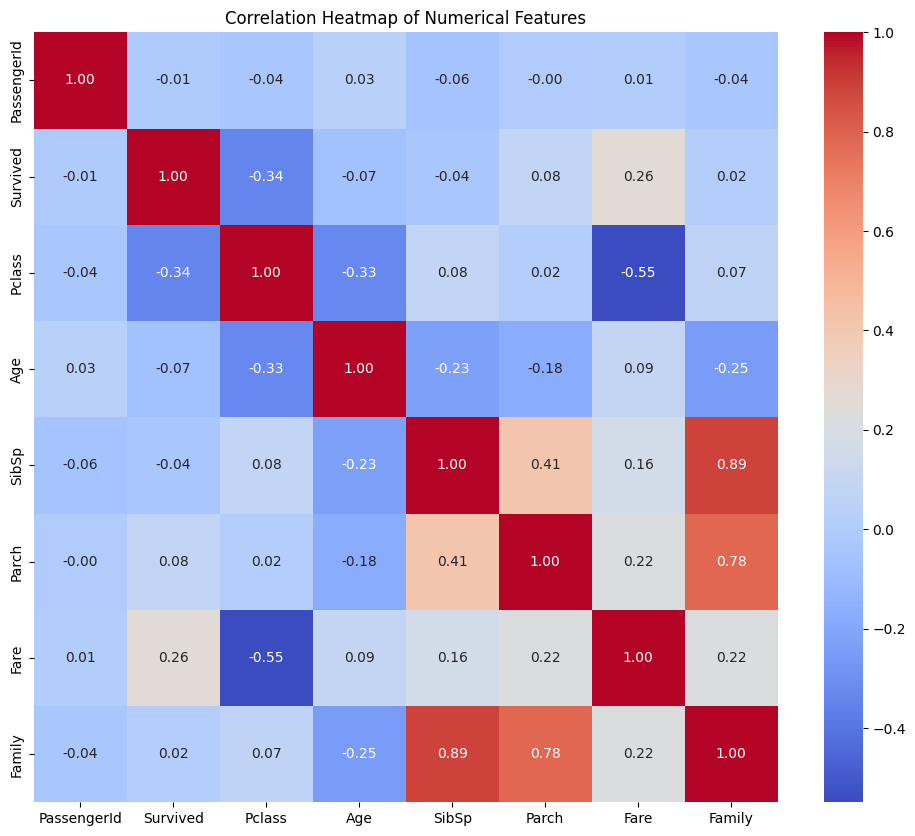

In [24]:
# TODO: Create a heatmap of correlation between numerical features

correlation_matrix = df.select_dtypes(include='number').corr()
plt.figure(figsize=(12, 10))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap of Numerical Features')
plt.show()

The correlation heatmap illustrates relationships between numerical features in the Titanic dataset.

The heatmap helps identify relationships between variables, although correlation does not necessarily imply causation.

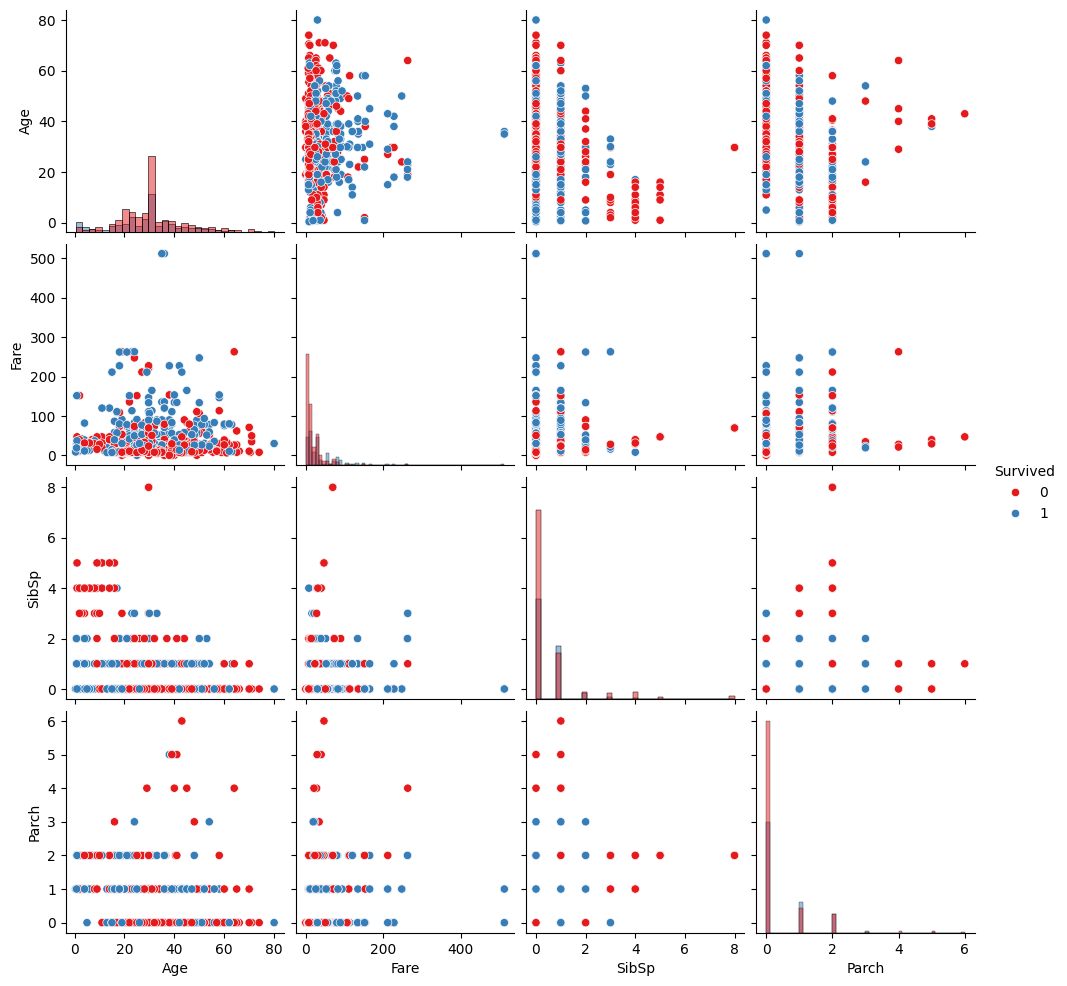

In [25]:
# TODO: Create a pair plot of 'Age', 'Fare', 'SibSp', and 'Parch', colored by 'Survived'
sns.pairplot(
    df,
    vars=['Age', 'Fare', 'SibSp', 'Parch'],
    hue='Survived',
    diag_kind='hist',
    palette='Set1'
)

plt.show()

The pair plot visualizes relationships between Age, Fare, SibSp, and Parch, categorized by survival status.

The plots help compare the distributions of passengers who survived and those who did not.

In [ ]:
# Task 8: Analyze survival rates

# TODO: Calculate and display survival rates by sex
# survival_by_sex = ...

# TODO: Calculate and display survival rates by passenger class
# survival_by_class = ...


In [ ]:
# Task 9: Analyze age distribution

# TODO: Create a box plot of age distribution by passenger class and sex
# plt.figure(figsize=(12, 6))
# ...
# plt.title('Age Distribution by Passenger Class and Sex')
# plt.show()

In [ ]:
# Task 10: Analyze fare distribution

# TODO: Create a violin plot of fare distribution by passenger class and survival status
# plt.figure(figsize=(12, 6))
# ...
# plt.title('Fare Distribution by Passenger Class and Survival Status')
# plt.show()

print("EDA tasks completed.")